In [1]:
from langchain_openai import ChatOpenAI

from dotenv import load_dotenv
import os
load_dotenv()

if os.environ['OPENAI_API_KEY'] :
    print("OpenAI API key is set.")
else:
    print("OpenAI API key is not set.")

OpenAI API key is set.


In [4]:
from langchain_core.messages import HumanMessage
llm = ChatOpenAI(model="gpt-5-nano")
llm.invoke([HumanMessage(content="i WANT TO KNOW THE MEANING OF WATER")]).content

'Here are the main meanings of water:\n\n- Scientific meaning\n  - Water is a chemical substance with the formula H2O. It consists of two hydrogen atoms bonded to one oxygen atom.\n  - It is a polar molecule, exists as a liquid at most Earth-normal temperatures, and is essential for all known life.\n  - It acts as a universal solvent, has a high heat capacity, and changes state (ice, liquid water, and steam).\n\n- Everyday meaning\n  - The clear liquid you drink, bathe in, wash with, and use for farming and cleaning. It is found in oceans, rivers, lakes, rain, and humidity.\n\n- Symbolic or cultural meaning\n  - Water often symbolizes life, purity, cleansing, change, and flow. Its meaning can vary by culture and context.\n\n- Etymology (word origin)\n  - The word “water” comes from Old English wæter, related to German Wasser, Dutch water, and other Germanic languages. They trace back to Proto-Germanic and ultimately Proto-Indo-European roots meaning “water.”\n\nIf you tell me which mea

In [6]:
from typing import List, TypedDict
from typing import Annotated
from operator import add
class graph_schema(TypedDict):

    message_manual: List
    message_auto: Annotated[List,add]


In [13]:
from langchain_core.messages import AIMessage;
def create_post(state: graph_schema)-> graph_schema:

    message_manual = state['message_manual']

    response_manual=llm.invoke(message_manual).content
    response_manual_ai = AIMessage(content=response_manual)
    state['message_manual'] = message_manual + [response_manual_ai]
    return state

def curate_post(state: graph_schema)-> graph_schema:

    message_manual = state['message_manual']

    response_manual=llm.invoke(message_manual).content
    response_manual_ai = AIMessage(content=response_manual)
    state['message_manual'] = message_manual + [response_manual_ai]
    return state


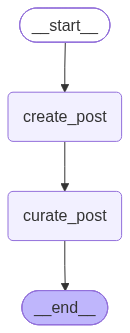

In [14]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("create_post",create_post)
graph.add_node("curate_post",curate_post)

graph.add_edge(START,"create_post")
graph.add_edge("create_post", "curate_post")
graph.add_edge("curate_post", END)

message_graph = graph.compile()

from IPython.display import display, Image

first_graph=graph.compile()

Image(first_graph.get_graph().draw_mermaid_png())


In [15]:
message_graph.invoke({"message_manual": [HumanMessage(content="The importance of AI in modern technology is significant.")]} )

{'message_manual': [HumanMessage(content='The importance of AI in modern technology is significant.', additional_kwargs={}, response_metadata={}),
  AIMessage(content="You're right—the importance of AI in modern technology is significant and expanding across nearly every domain. Here are the key reasons and impacts:\n\n- Data-driven decision making at scale: AI can analyze large, complex datasets far faster than humans, enabling better insights and faster decisions.\n- Automation and productivity: AI-powered automation handles repetitive or dangerous tasks, freeing people for higher-value work.\n- Personalization and user experience: AI enables highly tailored recommendations, services, and interactions at scale.\n- Accelerated R&D and innovation: AI supports simulations, optimization, generative design, and rapid prototyping in fields like chemistry, materials science, and software.\n- Operational efficiency and safety: Predictive maintenance, anomaly detection, and autonomous systems